### Cell 1: imports

In [7]:
import os, heapq, itertools, time, warnings
from datetime import date

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import gymnasium as gym
from gymnasium import spaces
from stable_baselines3.common.vec_env import SubprocVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from sb3_contrib import MaskablePPO
from sb3_contrib.common.wrappers import ActionMasker

### PDE, grid and exact solution
Burgers $u_t + u\,u_x = \alpha u_{xx}$ on $[0,1]$, $\alpha = 0.1$, $T = 0.5$, $u(x,0) = 1 + 0.8\cos\big(2\pi(x-0.5)/1.5\big)$ (peak at $x = 0.5$).
Dirichlet data at both walls from the exact solution (Hopf–Cole), given like the IC. The exact solution is only used for checks and reports, never by the agent.

alpha = 0.1, T = 0.5 | nx = 50, nt = 138, dx = 0.02041, dt = 3.650e-03 | r = 0.88, nu_max = 0.32, 2r + nu^2 = 1.86
check: FD 1x finer vs u_true at t = 0.25: max error 1.9e-03
check: FD 2x finer vs u_true at t = 0.25: max error 4.7e-04
check: FD 4x finer vs u_true at t = 0.25: max error 1.2e-04


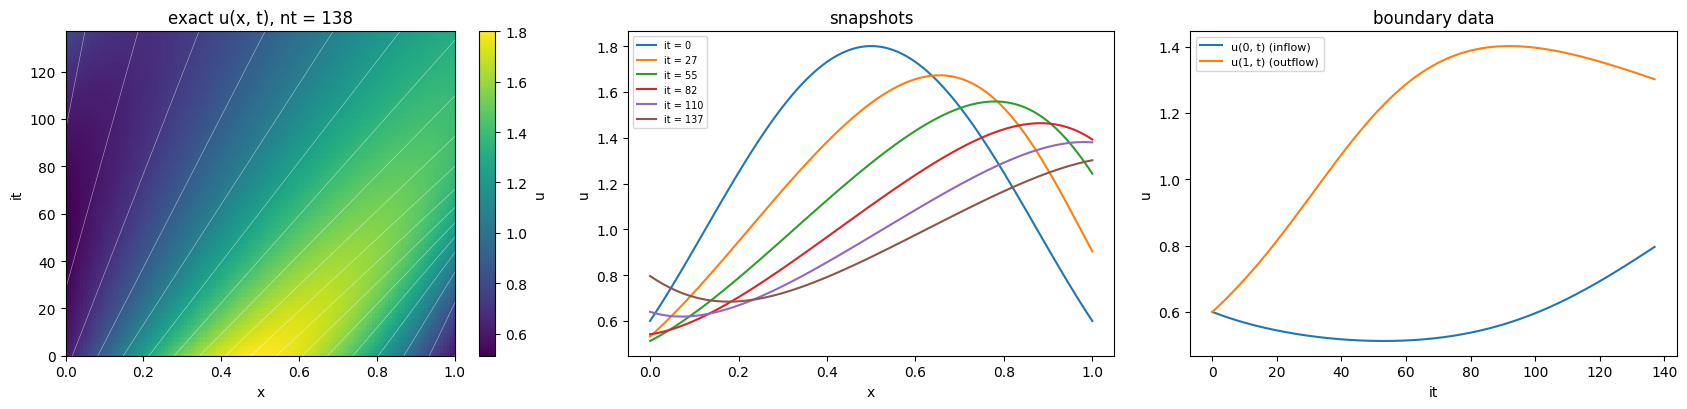

In [8]:
# ── PDE:  u_t + a(u) u_x = alpha u_xx  on [0, 1] ──
alpha, T = 0.1, 0.5
a = lambda u: u                                # advection speed: Burgers
C_BG, A_W, L_W, X_PK = 1.0, 0.8, 1.5, 0.5      # background, amplitude, wavelength, peak position: u stays in [0.2, 1.8] > 0
u0 = lambda x: C_BG + A_W * np.cos(2 * np.pi * (x - X_PK) / L_W)
F0 = lambda x: C_BG * x + A_W * L_W / (2 * np.pi) * (np.sin(2 * np.pi * (x - X_PK) / L_W) + np.sin(2 * np.pi * X_PK / L_W))  # integral of u0 from 0
A_MAX = C_BG + A_W

# ── Grid: explicit LW / FD-3 stable for 2r + nu^2 <= 1 (r = alpha dt/dx^2, nu = A_MAX dt/dx); 0.9 for margin ──
#    then DT_FACTOR x that time step: past the explicit limit (FD-3 / LW blow up), our 5-point stencils stay admissible
nx = 50
dx = 1.0 / (nx - 1)
_c2, _c1 = (A_MAX / dx)**2, 2 * alpha / dx**2
nt = int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2)))) + 1
DT_FACTOR = 2
nt = (nt - 1) // DT_FACTOR + 1
dt = T / (nt - 1)
x_grid = np.arange(nx) * dx

# ── Exact solution (Hopf-Cole) as a weighted average, accurate for small alpha too ──
#    u(x, t) = sum (x - y)/t W / sum W,  W = exp(-F0(y)/(2 alpha) - (x - y)^2 / (4 alpha t)),  y on a fine uniform grid
#    covering the feet of the characteristics (A_MAX T to the left) plus 8 kernel widths
_s  = 8 * np.sqrt(2 * alpha * T)
_lo, _hi = -A_MAX * T - _s, 1 + _s
_Y  = np.linspace(_lo, _hi, int(round((_hi - _lo) * 10000)) + 1)
_FY = F0(_Y) / (2 * alpha)

def u_true(x, t):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    if t <= 0:
        return u0(x)
    out = np.empty(len(x))
    for i in range(0, len(x), 50):                             # chunks of x, to keep memory small
        xs = x[i:i + 50, None]
        E  = -_FY - (xs - _Y)**2 / (4 * alpha * t)
        W  = np.exp(E - E.max(axis=1, keepdims=True))
        out[i:i + 50] = ((xs - _Y) / t * W).sum(1) / W.sum(1)
    return out

# exact values on the grid, one time level at a time when first needed (checks, reports and wall data only)
_U_rows = {}
def U_row(it):
    if it not in _U_rows:
        _U_rows[it] = u_true(x_grid, it * dt)
    return _U_rows[it]
Ug = lambda q: U_row(q[1])[q[0]]

# ── Boundary data u(0, t), u(1, t): exact on grid levels; a cubic spline in t between levels (refined classical schemes) ──
from scipy.interpolate import CubicSpline
_tb = np.linspace(0.0, T, 2001)
_gb = np.array([u_true([0.0, 1.0], t) for t in _tb])
_gs = CubicSpline(_tb, _gb)
g_left  = lambda t: float(_gs(t)[0])
g_right = lambda t: float(_gs(t)[1])

r_, nu_ = alpha * dt / dx**2, A_MAX * dt / dx
print(f"alpha = {alpha}, T = {T} | nx = {nx}, nt = {nt}, dx = {dx:.5f}, dt = {dt:.3e} | "
      f"r = {r_:.2f}, nu_max = {nu_:.2f}, 2r + nu^2 = {2 * r_ + nu_**2:.2f}")

# ── Check: explicit FD on finer grids converges to u_true (error / 4 per halving) ──
def _fd_fine(k, t_end):
    n, h = (nx - 1) * k + 1, dx / k
    steps = int(np.ceil(t_end / min(0.2 * h**2 / alpha, 0.5 * h / A_MAX))); s = t_end / steps
    u = u0(np.arange(n) * h)
    for j in range(steps):
        u[1:-1] = u[1:-1] + alpha * s / h**2 * (u[2:] - 2 * u[1:-1] + u[:-2]) - u[1:-1] * s / (2 * h) * (u[2:] - u[:-2])
        u[0], u[-1] = g_left((j + 1) * s), g_right((j + 1) * s)
    return u[::k]
for k in (1, 2, 4):
    print(f"check: FD {k}x finer vs u_true at t = {T / 2:.2f}: max error {np.abs(_fd_fine(k, T / 2) - u_true(x_grid, T / 2)).max():.1e}")

# ── Pictures: u(x, t) with characteristics, snapshots, boundary data ──
xf  = np.linspace(0, 1, 121)
its = np.linspace(0, nt - 1, 81).round().astype(int)
Uxt = np.array([u_true(xf, it * dt) for it in its])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
im = axes[0].pcolormesh(xf, its, Uxt, shading="auto", cmap="viridis")
fig.colorbar(im, ax=axes[0], label="u")
for x_0 in np.linspace(-A_MAX * T, 1, 30):                     # characteristics x = x_0 + u0(x_0) t
    axes[0].plot(x_0 + u0(x_0) * its * dt, its, "w-", lw=0.4, alpha=0.6)
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, nt - 1)
axes[0].set_xlabel("x"); axes[0].set_ylabel("it"); axes[0].set_title(f"exact u(x, t), nt = {nt}")
for it in np.linspace(0, nt - 1, 6).round().astype(int):
    axes[1].plot(xf, u_true(xf, it * dt), label=f"it = {it}")
axes[1].set_xlabel("x"); axes[1].set_ylabel("u"); axes[1].legend(fontsize=7); axes[1].set_title("snapshots")
axes[2].plot(_tb / dt, _gb[:, 0], label="u(0, t) (inflow)")
axes[2].plot(_tb / dt, _gb[:, 1], label="u(1, t) (outflow)")
axes[2].set_xlabel("it"); axes[2].set_ylabel("u"); axes[2].legend(fontsize=8); axes[2].set_title("boundary data")
plt.tight_layout(); plt.show()

### Taylor weights
A stencil of $n$ neighbours at offsets $(\Delta x_q, \Delta t_q)$ gets weights from 3 Taylor rows (value, $u_x$, $u_{xx}$), with $u_t = \alpha u_{xx} - a u_x$ substituted (moving frame $\xi = \Delta x - a\Delta t$). Min-norm solution; admissible if rank 3, $\mathrm{cond} \le 10^4$ and $\|w\|_1 \le 2$.

In [9]:
# ── Taylor predictor: 3 rows (value, u_x, u_xx) with u_t = alpha u_xx - a u_x substituted ──
COND_MAX, W_MAX = 1e4, 2.0
N_SOLVES = [0]                                                        # weight systems solved so far (cost metric)
def solve_weights_many(DX, DT, a_loc):
    """Min-norm weights for M stencils at once: DX, DT of shape (M, n) = neighbour offsets, a_loc = local speed.
    Returns W (M, n) and ok (M,): admissible = rank 3, cond <= COND_MAX and ||w||_1 <= W_MAX."""
    N_SOLVES[0] += DX.shape[0]                                        # one solve per stencil
    xi = DX - a_loc * DT                                              # offset in the moving frame
    h  = np.maximum(np.abs(DX).max(1), np.sqrt(alpha * np.abs(DT).max(1)))[:, None]
    A  = np.stack([np.ones_like(DX), xi / h, (0.5 * xi**2 + alpha * DT) / h**2], axis=1)   # (M, 3, n)
    s  = np.linalg.svd(A, compute_uv=False)                           # singular values, largest first
    ok = (s[:, -1] > s[:, 0] * DX.shape[1] * np.finfo(float).eps) & (s[:, 0] <= COND_MAX * s[:, -1])
    W  = np.linalg.pinv(A) @ np.array([1.0, 0.0, 0.0])
    return W, ok & (np.abs(W).sum(1) <= W_MAX)

def solve_weights(dxs, dts, a_loc):
    """One stencil: weights, or None if not admissible."""
    W, ok = solve_weights_many(dxs[None], dts[None], a_loc)
    return W[0] if ok[0] else None

### Local error estimate (score)
The local error of a stencil at $p$ is $\delta_p=u_p-\sum_q w_q u_q$. Expanding each neighbour value in a Taylor series around $p$ (with $\sum_q w_q=1$):
$$\delta_p\approx-\sum_q w_q\,P_p(\Delta x_q,\Delta t_q),\qquad s_p=\Big|\sum_q w_q\,P_p(\Delta x_q,\Delta t_q)\Big| ,$$
with $P_p$ the Taylor polynomial of $u$ around $p$ up to weight 4 ($\Delta t$ counts like two $\Delta x$'s, since $\alpha\Delta t\sim\Delta x^2$):
$$P_p=u_x\Delta x+u_t\Delta t+\tfrac12u_{xx}\Delta x^2+u_{xt}\Delta x\Delta t+\tfrac12u_{tt}\Delta t^2+\tfrac16u_{xxx}\Delta x^3+\tfrac12u_{xxt}\Delta x^2\Delta t+\tfrac1{24}u_{xxxx}\Delta x^4 .$$
Time derivatives replaced using Burgers ($u_t=\alpha u_{xx}-u\,u_x$):

| | |
|---|---|
| $u_t$ | $\alpha u_{xx}-u\,u_x$ |
| $u_{xt}$ | $\alpha u_{xxx}-u\,u_{xx}-u_x^2$ |
| $u_{xxt}$ | $\alpha u_{xxxx}-u\,u_{xxx}-3u_xu_{xx}$ |
| $u_{tt}$ | $\alpha^2u_{xxxx}-2\alpha u\,u_{xxx}+u^2u_{xx}+2u_x(u\,u_x-2\alpha u_{xx})$ |

Check: random admissible stencils at random points, score with the **exact** derivatives vs the true local error.

300 admissible stencils, |u_x| from 0.01 to 3.43
corr(log score, log true error) = 0.92, median |score - true error| / true error = 0.04


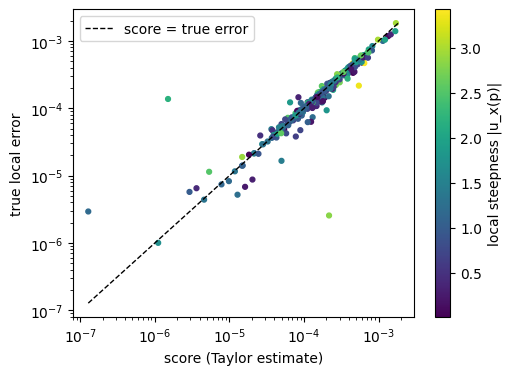

In [10]:
# ── Local error estimate (score): the stencil's error on the local Taylor polynomial of u around p ──
def taylor_coeffs(d):
    """d = (u, u_x, u_xx, u_xxx, u_xxxx) at p. Returns {(i, j): (d/dx)^i (d/dt)^j u / (i! j!)} for weight i + 2j <= 4."""
    u, u1, u2, u3, u4 = d
    ut   = alpha * u2 - u * u1
    uxt  = alpha * u3 - u * u2 - u1**2                                     # Burgers term: - u_x^2
    uxxt = alpha * u4 - u * u3 - 3 * u1 * u2                               # Burgers term: - 3 u_x u_xx
    utt  = alpha**2 * u4 - 2 * alpha * u * u3 + u**2 * u2 + 2 * u1 * (u * u1 - 2 * alpha * u2)   # Burgers term: 2 u_x (...)
    return {(1, 0): u1, (2, 0): u2 / 2, (3, 0): u3 / 6, (4, 0): u4 / 24,
            (0, 1): ut, (1, 1): uxt, (2, 1): uxxt / 2, (0, 2): utt / 2}

def score(DX, DT, w, d):
    """|sum_q w_q P(dx_q, dt_q)|, P = Taylor polynomial of u around p (without u_p). One stencil (n,) or M stencils (M, n)."""
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d).items())
    return np.abs((w * P).sum(-1))

def x_derivs(f, x, h=2e-3):
    """(u, u_x, u_xx, u_xxx, u_xxxx) of a function f at x, by 7-point central differences."""
    v = f(x + h * np.arange(-3, 4))
    C = [[0, 0, 0, 1, 0, 0, 0], np.array([-1, 9, -45, 0, 45, -9, 1]) / 60, np.array([2, -27, 270, -490, 270, -27, 2]) / 180,
         np.array([1, -8, 13, 0, -13, 8, -1]) / 8, np.array([-1, 12, -39, 56, -39, 12, -1]) / 6]
    return tuple(np.dot(c, v) / h**k for k, c in enumerate(C))

# ── Check: score vs the true local error, random admissible stencils at random interior points (u_true ONLY here) ──
U = lambda q: u_true(q[0] * dx, q[1] * dt)[0]
rng = np.random.default_rng(0)
cells = [(i, j) for j in (-1, -2, -3) for i in range(-3, 4)]               # 3 levels down, |dix| <= 3
S, D, G = [], [], []
while len(S) < 300:
    p = (int(rng.integers(3, nx - 3)), int(rng.integers(3, nt)))
    nb = [cells[k] for k in rng.choice(len(cells), 5, replace=False)]
    DX, DT = np.array([q[0] for q in nb]) * dx, np.array([q[1] for q in nb]) * dt
    d = x_derivs(lambda x: u_true(x, p[1] * dt), p[0] * dx)
    w = solve_weights(DX, DT, d[0])
    if w is None:
        continue
    u_nb = np.array([U((p[0] + q[0], p[1] + q[1])) for q in nb])
    S.append(score(DX, DT, w, d)); D.append(abs(U(p) - w @ u_nb)); G.append(abs(d[1]))
S, D, G = np.array(S), np.array(D), np.array(G)
print(f"300 admissible stencils, |u_x| from {G.min():.2f} to {G.max():.2f}")
print(f"corr(log score, log true error) = {np.corrcoef(np.log(S), np.log(D))[0, 1]:.2f}, "
      f"median |score - true error| / true error = {np.median(np.abs(S - D) / D):.2f}")

fig, ax = plt.subplots(figsize=(5.5, 4))
sc = ax.scatter(S, D, c=G, s=12, cmap="viridis")
lim = [min(S.min(), D.min()), max(S.max(), D.max())]
ax.loglog(lim, lim, 'k--', lw=1, label='score = true error')
fig.colorbar(sc, label="local steepness |u_x(p)|")
ax.set_xlabel('score (Taylor estimate)'); ax.set_ylabel('true local error'); ax.legend(); plt.show()

guess: 629 points (17 in x)
median relative error of the guess for u, u_x, u_xx, u_xxx, u_xxxx: 0.011  0.023  0.036  0.034  0.084


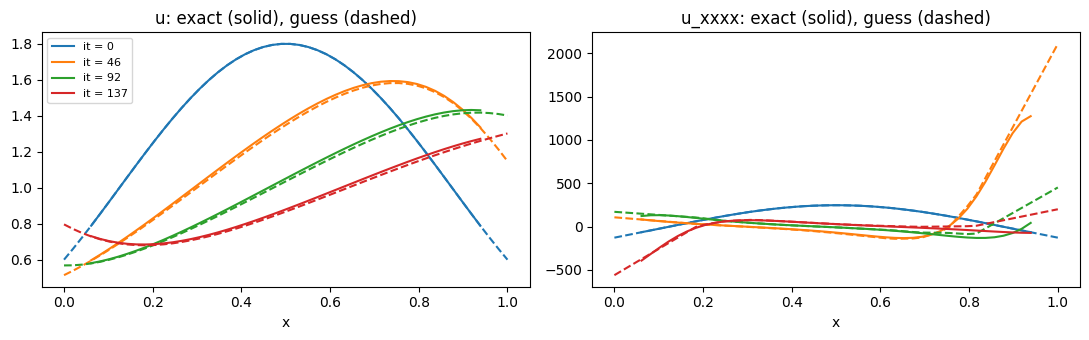

In [12]:
# ── Rough guess of u and its x-derivatives, used ONLY to build the map (speed, weights, score) ──
from scipy.interpolate import make_interp_spline
K_COARSE = 3

def make_guess(K):
    """LW on a grid K times coarser, fitted with a spline in x and linear in t onto our grid.
    Returns GUESS[k, it, ix] (k-th x-derivative at grid point (ix, it)), its cost in grid points, the coarse x and dt."""
    xc  = np.linspace(0.0, 1.0, (nx - 1) // K + 1)
    hc  = xc[1] - xc[0]
    c2, c1 = (A_MAX / hc)**2, 2 * alpha / hc**2                                   # same stability rule as the main grid
    tau = T / int(np.ceil(T / ((-c1 + np.sqrt(c1**2 + 4 * c2 * 0.9)) / (2 * c2))))
    tc  = np.arange(0.0, T + tau / 2, tau)
    Uc  = [u0(xc)]
    for j in range(1, len(tc)):
        u, ui = Uc[-1], Uc[-1][1:-1]
        r, nu = alpha * tau / hc**2, a(ui) * tau / hc
        n = u.copy()
        n[1:-1] = ui + (r + nu**2 / 2) * (u[2:] - 2 * ui + u[:-2]) - nu / 2 * (u[2:] - u[:-2])
        n[0], n[-1] = g_left(tc[j]), g_right(tc[j])                               # boundary data
        Uc.append(n)
    Dc = np.zeros((5, len(tc), nx))                                               # (derivative order, coarse time, our x)
    for j, u in enumerate(Uc):
        sp = make_interp_spline(xc, u, k=min(5, len(xc) - 1))                     # quintic
        for k in range(5):
            Dc[k, j] = sp.derivative(k)(x_grid) if k else sp(x_grid)
    tg = np.arange(nt) * dt
    jj = np.minimum((tg // tau).astype(int), len(tc) - 2)
    f  = ((tg - tc[jj]) / tau)[None, :, None]
    return (1 - f) * Dc[:, jj] + f * Dc[:, jj + 1], len(xc) * len(tc), xc, tau

GUESS, G_COARSE, xc, tau = make_guess(K_COARSE)
guess_derivs = lambda q: GUESS[:, q[1], q[0]]                                     # (u, u_x, u_xx, u_xxx, u_xxxx) at q

# ── Check: guessed derivatives vs exact at 300 random points (u_true ONLY here) ──
print(f"guess: {G_COARSE} points ({len(xc)} in x)")
rng = np.random.default_rng(0)
pts = [(int(rng.integers(3, nx - 3)), int(rng.integers(1, nt))) for _ in range(300)]
ex  = np.array([x_derivs(lambda x: u_true(x, q[1] * dt), q[0] * dx) for q in pts])
gs  = np.array([guess_derivs(q) for q in pts])
rel = np.abs(gs - ex) / (np.abs(ex) + 1e-12)
print("median relative error of the guess for u, u_x, u_xx, u_xxx, u_xxxx: " + "  ".join(f"{v:.3f}" for v in np.median(rel, axis=0)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i, it in enumerate([0, nt // 3, 2 * nt // 3, nt - 1]):
    ex_ = np.array([x_derivs(lambda x: u_true(x, it * dt), xx) for xx in x_grid[3:-3]])
    for ax, k in zip(axes, [0, 4]):
        ax.plot(x_grid[3:-3], ex_[:, k], color=f"C{i}", label=f"it = {it}")
        ax.plot(x_grid, GUESS[k, it], "--", color=f"C{i}")
axes[0].set_title("u: exact (solid), guess (dashed)"); axes[1].set_title("u_xxxx: exact (solid), guess (dashed)")
for ax in axes: ax.set_xlabel("x")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

z* = (25, 37): pass 1 = 172 points | LW guess up to t* = 170 points
   pass 1  median rel. error u 0.001  u_x 0.005  u_xx 0.012  u_xxx 0.049  u_xxxx 0.222
   LW      median rel. error u 0.003  u_x 0.009  u_xx 0.023  u_xxx 0.045  u_xxxx 0.215
z* = (25, 75): pass 1 = 364 points | LW guess up to t* = 340 points
   pass 1  median rel. error u 0.002  u_x 0.006  u_xx 0.029  u_xxx 0.066  u_xxxx 0.343
   LW      median rel. error u 0.006  u_x 0.017  u_xx 0.033  u_xxx 0.049  u_xxxx 0.113


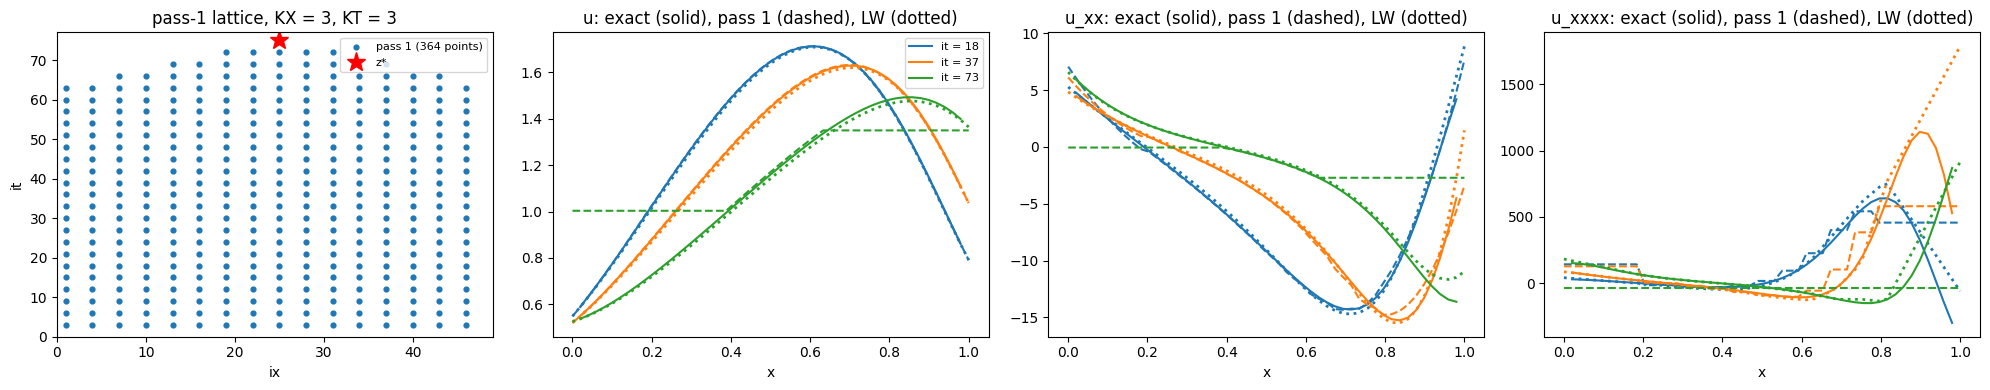

In [13]:
# ── Pass 1: a coarse UNIFORM backward map of z*, used ONLY for the guess (its values never enter u_hat(z*)) ──
#   lattice: every KX-th column and KT-th level, rooted at z*; each lattice point uses the 5 lattice points one coarse
#   level below (offsets -2..2 coarse columns), clamped onto the walls / IC (known data: exact values, like the IC)
#   values bottom-up with our Taylor weights; first speed = value of the point right below, then Picard re-solves
from math import factorial
KX, KT, P1_PICARD = 3, 3, 2

def pass1(z):
    """Values of z*'s coarse backward map {(ix, it): u} (lattice points only, known data excluded)."""
    clamp  = lambda q: (min(max(q[0], 0), nx - 1), max(q[1], 0))
    known  = lambda q: q[1] == 0 or q[0] in (0, nx - 1)
    nbs_of = lambda p: list(dict.fromkeys(clamp((p[0] + d * KX, p[1] - KT)) for d in (-2, -1, 0, 1, 2)))
    pts, todo = set(), [z]                                       # backward: the lattice points z* needs
    while todo:
        p = todo.pop()
        if p not in pts and not known(p):
            pts.add(p); todo += nbs_of(p)
    val = {}
    get = lambda q: Ug(q) if known(q) else val[q]
    for p in sorted(pts, key=lambda p: p[1]):                    # forward: bottom-up
        nbs = nbs_of(p)
        v   = np.array([get(q) for q in nbs])
        DX, DT = np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt
        u_p = get(clamp((p[0], p[1] - KT)))                      # first speed: the point right below
        for _ in range(1 + P1_PICARD):
            w = solve_weights(DX, DT, a(u_p))
            if w is None:                                        # not admissible: keep the last value
                break
            u_p = w @ v
        val[p] = u_p
    return val

def guess_pass1(z):
    """GUESS[k, it, ix] (k-th x-derivative) for it <= it*, and pass 1's point count.
    On each lattice level below z*: a local quartic in x (least squares through the 7 nearest lattice points, x clamped
    to the level's end points); linear in t between levels; levels above the top lattice level hold its guess."""
    val = pass1(z)
    rows = {0: (np.arange(nx) * dx, u0(np.arange(nx) * dx))}     # the IC level: known everywhere
    for it in {q[1] for q in val if q[1] < z[1]}:
        qs = sorted(q for q in val if q[1] == it)
        qs = [(0, it)] * (qs[0][0] <= 2 * KX) + qs + [(nx - 1, it)] * (qs[-1][0] >= nx - 1 - 2 * KX)   # walls the level reaches
        rows[it] = (np.array([q[0] for q in qs]) * dx, np.array([Ug(q) if q[0] in (0, nx - 1) else val[q] for q in qs]))
    D = {}
    for it, (xs, us) in rows.items():
        D[it] = np.zeros((5, nx))
        for ix in range(nx):
            x    = min(max(ix * dx, xs[0]), xs[-1])
            near = np.argsort(np.abs(xs - x))[:7]
            c    = np.polynomial.polynomial.polyfit(xs[near] - x, us[near], min(4, len(near) - 1))   # c[k] = u^(k)(x) / k!
            D[it][:len(c), ix] = c * [factorial(k) for k in range(len(c))]
    L = sorted(D)
    G = np.zeros((5, z[1] + 1, nx))
    for it in range(z[1] + 1):
        if it >= L[-1]:
            G[:, it] = D[L[-1]]
        else:
            lo = max(l for l in L if l <= it); hi = min(l for l in L if l > it)
            f  = (it - lo) / (hi - lo)
            G[:, it] = (1 - f) * D[lo] + f * D[hi]
    return G, len(val)

# ── Check: pass-1 guess vs the LW guess (GUESS, cell above) inside z*'s cone (u_true ONLY here) ──
rng = np.random.default_rng(0)
NAMES = ("u", "u_x", "u_xx", "u_xxx", "u_xxxx")
P1 = {}
for z in [(25, 37), (25, 75)]:
    G1, n1 = guess_pass1(z)
    P1[z] = G1
    cone = [(ix, it) for it in range(1, z[1]) for ix in range(max(1, z[0] - (z[1] - it)), min(nx - 1, z[0] + z[1] - it + 1))]
    pts  = [cone[i] for i in rng.choice(len(cone), min(300, len(cone)), replace=False)]
    ex   = np.array([x_derivs(lambda x: u_true(x, q[1] * dt), q[0] * dx) for q in pts])
    rel  = lambda Gs: np.median(np.abs(np.array([Gs[:, q[1], q[0]] for q in pts]) - ex) / (np.abs(ex) + 1e-12), axis=0)
    print(f"z* = {z}: pass 1 = {n1} points | LW guess up to t* = {len(xc) * (int(z[1] * dt / tau) + 1)} points")
    for name, Gs in [("pass 1", G1), ("LW", GUESS)]:
        print(f"   {name:7s} median rel. error " + "  ".join(f"{n} {v:.3f}" for n, v in zip(NAMES, rel(Gs))))

# ── Pictures: pass-1 lattice of the larger query; exact vs pass 1 vs LW for u, u_xx, u_xxxx on three levels ──
z = (25, 75)
val = pass1(z)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].scatter([q[0] for q in val], [q[1] for q in val], s=12, c="tab:blue", label=f"pass 1 ({len(val)} points)")
axes[0].plot(*z, "r*", ms=14, label="z*"); axes[0].set_xlim(0, nx - 1); axes[0].set_ylim(0, z[1] + 2)
axes[0].set_xlabel("ix"); axes[0].set_ylabel("it"); axes[0].legend(fontsize=8); axes[0].set_title(f"pass-1 lattice, KX = {KX}, KT = {KT}")
for i, it in enumerate([z[1] // 4, z[1] // 2, z[1] - 2]):
    ex_ = np.array([x_derivs(lambda x: u_true(x, it * dt), xx) for xx in x_grid[1:-1]])
    for ax, k in zip(axes[1:], [0, 2, 4]):
        ax.plot(x_grid[1:-1], ex_[:, k], color=f"C{i}", label=f"it = {it}")
        ax.plot(x_grid, P1[z][k, it], "--", color=f"C{i}")
        ax.plot(x_grid, GUESS[k, it], ":", color=f"C{i}", lw=2)
for ax, k in zip(axes[1:], [0, 2, 4]):
    ax.set_title(f"{NAMES[k]}: exact (solid), pass 1 (dashed), LW (dotted)"); ax.set_xlabel("x")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

### Backward map, influence β, forward pass
**Map.** Start at $z^*$ and give it a stencil; every neighbour that is not known data (IC or wall) becomes a pending point. Points are expanded **latest $t$ first**, until every branch ends on the IC or a wall.
**Weights** use $p$'s guessed speed, rounded to 0.02 so they can be cached by (shape, speed).
**Influence.** $\beta_{z^*}=1$; when $p$ is expanded, $\beta_q \mathrel{+}= \beta_p w_q$. All users of $p$ are on higher levels, so $\beta_p$ is final when $p$ is expanded.
**Forward pass.** Values bottom-up, $\hat u_p=\sum_q w_q\hat u_q$; each point re-solves its weights with the speed of its own value (3 Picard steps), so no guessed value enters $\hat u$.
**Identity.** With $\delta_p=u_p-\sum_q w_qu_q$: $\;e(z^*)=\sum_p\beta_p\delta_p$, exact. Check with the Lax–Wendroff stencil everywhere.

In [15]:
# ── Known data: IC and walls (exact values there) ──
is_known    = lambda q: q[1] == 0 or q[0] in (0, nx - 1)
known_value = Ug
PICARD = 1                                       # forward-pass steps: 1 is within 1% of converged (cell 8 check)

# ── Speed at p for its weights: from the guess, rounded to A_STEP so weights can be cached ──
A_STEP  = 0.02
a_build = lambda p: A_STEP * round(a(guess_derivs(p)[0]) / A_STEP)

_w_cache = {}
def weights(p, nbs):
    """Taylor weights of p's neighbours nbs with p's guessed speed; None if not admissible. Cached by (shape, speed);
    solved with the neighbours sorted, so the result does not depend on the order they were picked in."""
    order = sorted(range(len(nbs)), key=lambda i: (-nbs[i][1], nbs[i][0]))
    offs  = tuple((nbs[i][0] - p[0], nbs[i][1] - p[1]) for i in order)
    key   = (offs, a_build(p))
    if key not in _w_cache:
        _w_cache[key] = solve_weights(np.array([o[0] for o in offs]) * dx, np.array([o[1] for o in offs]) * dt, key[1])
    if _w_cache[key] is None:
        return None
    w = np.empty(len(nbs)); w[order] = _w_cache[key]
    return w
 
score_derivs = lambda p: (a_build(p),) + tuple(guess_derivs(p)[1:])   # u = the rounded speed the weights use: score and weights agree

def point_score(p, nbs, w):
    """Estimated local error of p's stencil, with the guessed derivatives at p (u = p's rounded speed)."""
    return score(np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt, w, score_derivs(p))
# ── The map, built backward from z*: pending points expanded latest t first ──
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], z_star[0])], "beta": {z_star: 1.0}, "stencil": {}, "stopped": set()}
def next_point(m):
    it, ix = m["pending"][0]
    return (ix, -it)

def pending_points(m):
    return [(ix, -it) for it, ix in m["pending"]]

def expand(m, nbs):
    """Give the next point the stencil nbs and pass its influence down. Returns (p, w)."""
    it, ix = heapq.heappop(m["pending"])
    p = (ix, -it)
    w = weights(p, nbs)
    m["stencil"][p] = (nbs, w)
    for q, wq in zip(nbs, w):
        if not is_known(q):
            if q not in m["beta"]:
                m["beta"][q] = 0.0
                heapq.heappush(m["pending"], (-q[1], q[0]))
            m["beta"][q] += m["beta"][p] * wq
    return p, w

def build_map(z_star, choose):
    """Whole map; choose(m, p) returns the neighbours of p, or None to stop p (cell 9)."""
    m = start_map(z_star)
    while m["pending"]:
        nbs = choose(m, next_point(m))
        stop_point(m) if nbs is None else expand(m, nbs)
    return m

# ── Forward pass: values bottom-up; each point re-solves its weights with the speed of its own value (Picard) ──
def evaluate(m, picard=PICARD):
    u_hat, m["w_used"] = {}, {}
    value = lambda q: known_value(q) if is_known(q) else u_hat[q]
    for p in sorted(m["stencil"], key=lambda p: p[1]):
        nbs, w = m["stencil"][p]
        v = np.array([value(q) for q in nbs])
        DX, DT = np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt
        for _ in range(picard):
            w_new = solve_weights(DX, DT, a(w @ v))             # speed from the value just computed
            if w_new is None:                                   # not admissible: keep the last weights
                break
            w = w_new
        m["w_used"][p], u_hat[p] = w, w @ v
    return u_hat

# ── Reference map: one fixed 5-point stencil on the level below (LW's 3-point one is not admissible at 2 dt, r > 1/2) ──
wide = lambda m, p: list(dict.fromkeys((min(max(p[0] + d, 0), nx - 1), p[1] - 1) for d in (-2, -1, 0, 1, 2)))

# ── Check: the wide stencil everywhere; the identity must hold to all digits (map weights, picard=0) ──
for z in [(10, 20), (25, 37)]:
    m = build_map(z, wide)
    err = Ug(z) - evaluate(m, picard=0)[z]
    delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
    print(f"wide-5 map at z* = {z}: {len(m['stencil'])} points | e(z*) = {err:.6e}, sum beta*delta = "
          f"{sum(m['beta'][p] * delta[p] for p in delta):.6e} | with {PICARD} Picard steps: error {abs(Ug(z) - evaluate(m)[z]):.2e}")

wide-5 map at z* = (10, 20): 555 points | e(z*) = -6.178917e-04, sum beta*delta = -6.178917e-04 | with 1 Picard steps: error 3.87e-04
wide-5 map at z* = (25, 37): 1476 points | e(z*) = -9.119682e-04, sum beta*delta = -9.119682e-04 | with 1 Picard steps: error 1.09e-03


### Window, admissible stencils, mask, report
**Window.** Candidate neighbours of $p$: the 21 cells $|\Delta i_x|\le3$, 1–3 levels below. A cell past a wall or below $t=0$ is moved onto it (known data).
**Admissible stencils.** Every choice of 5 cells whose weights pass the test of cell 3, with $p$'s guessed speed. Cached by (local situation, speed) together with each stencil's **moments** $\sum_q w_q\Delta x_q^i\Delta t_q^j$; the score at $p$ is then the moments times the Taylor coefficients at $p$.
**Mask.** The agent picks the 5 cells one at a time; a cell may be picked only if some admissible stencil contains it with the picks so far.
**Lowest score:** every point takes its lowest-score stencil (a rule, no RL). **Report:** points, true error at $z^*$, exact bound $\sum_p|\beta_p\delta_p|$ (exact solution for reporting only).

21 window cells | interior point (25, 37): 17679 admissible stencils of 20349 | first pick allowed on 21 cells
wide-5      : 1476 points, error 1.09e-03, exact bound 1.13e-03  (0 s)
lowest score: 1354 points, error 1.16e-04, exact bound 4.56e-04  (12 s)


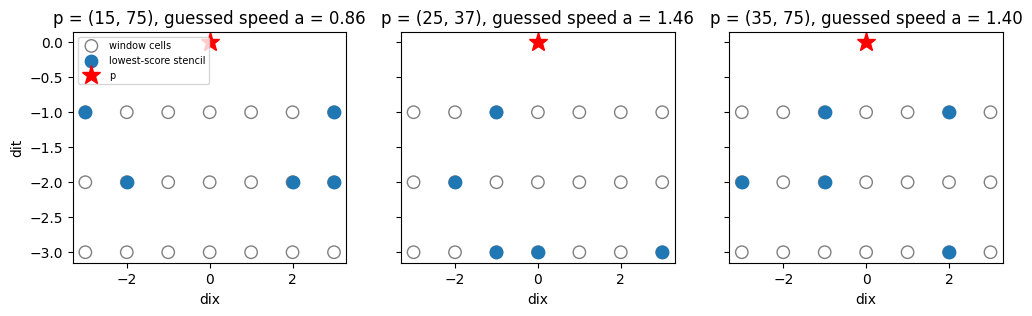

In [16]:
# ── The window: candidate neighbour cells below p ──
R_X, K_T = 3, 3                       # |dix| <= 3 cells, 1 to 3 levels down
WINDOW  = [(dix, dit) for dit in range(-1, -K_T - 1, -1) for dix in range(-R_X, R_X + 1)]
N_CELLS = len(WINDOW)
N_NB    = 5                           # neighbours per stencil
TERMS   = list(taylor_coeffs((0.0,) * 5))                             # the (i, j) Taylor terms of the score

def place(p, k):
    """Grid point of window cell k seen from p. Past a wall or below t = 0 -> moved onto it."""
    return (min(max(p[0] + WINDOW[k][0], 0), nx - 1), max(p[1] + WINDOW[k][1], 0))

# ── Every admissible stencil at p: cached by local situation and guessed speed (stencils, cell usage, moments) ──
_sets_cache = {}
def admissible(p):
    """(stencils as tuples of cells, cell-usage matrix, scores at p). Cells that land on the same point count once."""
    key = (tuple((place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)), a_build(p))
    if key not in _sets_cache:
        cells, seen = [], set()
        for k in range(N_CELLS):
            if place(p, k) not in seen:
                seen.add(place(p, k)); cells.append(k)
        sets = list(itertools.combinations(cells, min(N_NB, len(cells))))
        off  = np.array([[(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in s] for s in sets])   # (M, n, 2)
        DX, DT = off[..., 0] * dx, off[..., 1] * dt
        W, ok  = solve_weights_many(DX, DT, a_build(p))                # all candidate stencils in one solve
        sets   = [s for s, o in zip(sets, ok) if o]
        mom    = np.stack([(W[ok] * DX[ok]**i * DT[ok]**j).sum(1) for i, j in TERMS], axis=1)
        uses   = np.zeros((len(sets), N_CELLS), dtype=bool)
        for i, s in enumerate(sets):
            uses[i, list(s)] = True
        _sets_cache[key] = (sets, uses, mom)
    sets, uses, mom = _sets_cache[key]
    c = taylor_coeffs(score_derivs(p))
    return sets, uses, np.abs(mom @ np.array([c[t] for t in TERMS]))

def pick_mask(p, picks):
    """Cell k may be picked next if some admissible stencil contains the picks so far plus k."""
    _, uses, _ = admissible(p)
    ok = uses[:, picks].all(axis=1) if picks else np.ones(len(uses), dtype=bool)
    mask = uses[ok].any(axis=0)
    mask[picks] = False
    return mask

def lowest_score(m, p):
    sets, _, sc = admissible(p)
    return [place(p, k) for k in sets[int(np.argmin(sc))]]

# ── Report of a finished map, with the weights the forward pass used (u_true ONLY here) ──
def report(m, picard=PICARD):
    """Points, true error at z*, exact bound sum |beta delta| (beta recomputed with the weights actually used)."""
    z = m["z_star"]
    u_hat, W = evaluate(m, picard), m["w_used"]
    beta = {z: 1.0}
    for p in sorted(m["stencil"], key=lambda p: -p[1]):           # every user before the points it uses
        for q, wq in zip(m["stencil"][p][0], W[p]):
            if not is_known(q):
                beta[q] = beta.get(q, 0.0) + beta[p] * wq
    delta = {p: Ug(p) - W[p] @ np.array([Ug(q) for q in m["stencil"][p][0]]) for p in m["stencil"]}
    return {"points": len(m["stencil"]), "error": abs(Ug(z) - u_hat[z]),
            "bound": sum(abs(beta[p] * delta[p]) for p in delta)}

# ── Check ──
z = (25, 37)
sets, _, sc = admissible(z)
print(f"{N_CELLS} window cells | interior point {z}: {len(sets)} admissible stencils of "
      f"{len(list(itertools.combinations(range(N_CELLS), N_NB)))} | first pick allowed on {pick_mask(z, []).sum()} cells")
for name, rule in [("wide-5", wide), ("lowest score", lowest_score)]:
    t0 = time.time()
    rep = report(build_map(z, rule))
    print(f"{name:12s}: {rep['points']} points, error {rep['error']:.2e}, exact bound {rep['bound']:.2e}  ({time.time() - t0:.0f} s)")

    
# ── Picture: the lowest-score stencil at three points with different speeds ──
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, p in zip(axes, [(15, 75), (25, 37), (35, 75)]):
    sets, _, sc = admissible(p)
    best = sets[int(np.argmin(sc))]
    ax.scatter(*np.array(WINDOW).T, s=80, facecolors='none', edgecolors='gray', label='window cells')
    ax.scatter(*np.array([WINDOW[k] for k in best]).T, s=80, color='tab:blue', label='lowest-score stencil')
    ax.plot(0, 0, 'r*', ms=14, label='p')
    ax.set_title(f"p = {p}, guessed speed a = {a_build(p):.2f}"); ax.set_xlabel('dix')
axes[0].set_ylabel('dit'); axes[0].legend(fontsize=7, loc='upper left'); plt.show()

### Greedy and the cost of each rule
**Greedy**: at every point, the admissible stencil with the best one-step reward, $\;|\beta_p|s_p/\mathrm{EPS}+\lambda\,(\text{new points})/N_{\rm LW}$.
**Cost** of a map: points, and weight systems solved — for the stencil library (all candidates, once per local situation and speed, shared by every query), while building, and in the forward pass (1 Picard step per point). Cold = empty library, warm = library already filled.

In [17]:
# ── Reward units (also used by the environment) ──
EPS = 1e-3                                                        # accuracy unit
def n_lw(z):
    """Points unit: size of z*'s LW cone (one more column each side per level, walls excluded) = the LW map's
    point count at the explicit dt; counted directly because LW's 3-point stencil is not admissible at 2 dt."""
    return sum(min(nx - 2, z[0] + j) - max(1, z[0] - j) + 1 for j in range(z[1]))

def greedy_rule(lam):
    """At every point the admissible stencil with the best one-step reward (beta_p is final when p is expanded)."""
    def choose(m, p):
        sets, uses, sc = admissible(p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

# ── Cost of each rule at z*: points, weight solves (build, forward), time; library cold or warm ──
def cost_run(z, rule, cold):
    if cold:
        _sets_cache.clear(); _w_cache.clear()
    n0, t0 = N_SOLVES[0], time.time()
    m = build_map(z, rule)
    n_build, t_build = N_SOLVES[0] - n0, time.time() - t0
    rep = report(m)                                               # the forward pass (3 Picard steps) happens here
    return rep | {"solves_build": n_build, "solves_fwd": N_SOLVES[0] - n0 - n_build, "time": t_build}

z = (25, 37)
n_lw(z)
print(f"{'rule':14s} {'library':8s} {'points':>7s} {'error':>9s} {'bound':>9s} {'solves build':>13s} {'solves fwd':>11s} {'build time':>11s}")
for name, rule in [("wide-5", wide), ("lowest score", lowest_score), ("greedy lam=1", greedy_rule(1.0))]:
    for cold in (True, False):
        r = cost_run(z, rule, cold)
        print(f"{name:14s} {'cold' if cold else 'warm':8s} {r['points']:7d} {r['error']:9.2e} {r['bound']:9.2e} "
              f"{r['solves_build']:13,d} {r['solves_fwd']:11,d} {r['time']:10.1f}s")

        # ── How many Picard steps are needed? error and exact bound vs steps, same maps (0 = the build weights) ──
for name, rule in [("wide-5", wide), ("lowest score", lowest_score), ("greedy lam=1", greedy_rule(1.0))]:
    m = build_map(z, rule)
    reps = {k: report(m, picard=k) for k in (0, 1, 2, 3, 5)}
    print(f"{name:14s} | " + "  ".join(f"{k}: err {r['error']:.2e} bnd {r['bound']:.2e}" for k, r in reps.items()))

rule           library   points     error     bound  solves build  solves fwd  build time
wide-5         cold        1476  1.09e-03  1.13e-03            79       1,476        0.0s
wide-5         warm        1476  1.09e-03  1.13e-03             0       1,476        0.0s
lowest score   cold        1354  1.16e-04  4.56e-04     1,400,739       1,354       11.7s
lowest score   warm        1354  1.16e-04  4.56e-04             0       1,354        0.1s
greedy lam=1   cold         628  1.34e-05  4.58e-04     1,253,129         628       10.4s
greedy lam=1   warm         628  1.34e-05  4.58e-04             0         628        0.2s
wide-5         | 0: err 9.12e-04 bnd 1.76e-03  1: err 1.09e-03 bnd 1.13e-03  2: err 1.07e-03 bnd 1.12e-03  3: err 1.07e-03 bnd 1.12e-03  5: err 1.07e-03 bnd 1.12e-03
lowest score   | 0: err 2.04e-03 bnd 2.34e-03  1: err 1.16e-04 bnd 4.56e-04  2: err 8.98e-05 bnd 4.56e-04  3: err 9.02e-05 bnd 4.56e-04  5: err 9.01e-05 bnd 4.56e-04
greedy lam=1   | 0: err 2.04e-03 bnd 2

In [19]:
# ── Does the pass-1 guess change the maps? Lowest score and greedy built on each guess (u_true ONLY in the report) ──
#   same rules, same queries; only the guess differs. Guess cost: LW = its coarse points up to t*, pass 1 = its points
GUESS_LW = GUESS
lw_cost  = lambda z: len(xc) * (int(z[1] * dt / tau) + 1)
Z_TRAIN, TEST_QUERIES = (25, 37), [(ix, it) for it in (25, 50, 75) for ix in (12, 25, 38)]
RULES = {"lowest score": lowest_score, "greedy": greedy_rule(1.0)}

R = {}                                                            # R[guess, rule, z] = report + guess cost
for z in [Z_TRAIN] + TEST_QUERIES:
    G1, n1 = guess_pass1(z)
    for gname, G, gcost in [("LW", GUESS_LW, lw_cost(z)), ("pass 1", G1, n1)]:
        GUESS = G                                                 # guess_derivs reads the global GUESS
        for rname, rule in RULES.items():
            R[gname, rname, z] = report(build_map(z, rule)) | {"guess": gcost}
GUESS = GUESS_LW

print(f"{'z*':9s} {'rule':13s} | {'LW guess: pts+guess   error    bound':37s} | {'pass 1: pts+guess   error    bound'}")
for z in [Z_TRAIN] + TEST_QUERIES:
    for rname in RULES:
        a_, b_ = R["LW", rname, z], R["pass 1", rname, z]
        print(f"{str(z):9s} {rname:13s} | {a_['points']:5d}+{a_['guess']:<4d} {a_['error']:9.2e} {a_['bound']:9.2e}        | "
              f"{b_['points']:5d}+{b_['guess']:<4d} {b_['error']:9.2e} {b_['bound']:9.2e}")
gm = lambda v: float(np.exp(np.mean(np.log(v))))
for rname in RULES:
    ratio = lambda key: gm([R["pass 1", rname, z][key] / R["LW", rname, z][key] for z in TEST_QUERIES])
    tot   = gm([(R["pass 1", rname, z]["points"] + R["pass 1", rname, z]["guess"]) /
                (R["LW", rname, z]["points"] + R["LW", rname, z]["guess"]) for z in TEST_QUERIES])
    print(f"{rname:13s} pass 1 / LW over the 9 unseen (geo mean): points+guess {tot:.2f}, error {ratio('error'):.2f}, bound {ratio('bound'):.2f}")

z*        rule          | LW guess: pts+guess   error    bound  | pass 1: pts+guess   error    bound
(25, 37)  lowest score  |  1354+170   1.16e-04  4.56e-04        |  1365+172   8.45e-05  4.65e-04
(25, 37)  greedy        |   628+170   1.34e-05  4.58e-04        |   633+172   1.02e-04  4.01e-04
(12, 25)  lowest score  |   736+119   6.92e-05  1.90e-04        |   623+98    4.78e-05  1.71e-04
(12, 25)  greedy        |   301+119   3.66e-05  2.01e-04        |   298+98    7.74e-05  2.18e-04
(25, 25)  lowest score  |   805+119   1.02e-04  3.80e-04        |   774+108   4.11e-05  3.81e-04
(25, 25)  greedy        |   365+119   1.68e-05  3.20e-04        |   322+108   1.46e-04  3.85e-04
(38, 25)  lowest score  |   745+119   1.27e-04  7.32e-04        |   767+98    1.38e-04  7.57e-04
(38, 25)  greedy        |   284+119   3.89e-05  7.72e-04        |   336+98    1.67e-04  7.69e-04
(12, 50)  lowest score  |  1832+238   7.15e-05  1.82e-04        |  1845+226   4.64e-05  1.63e-04
(12, 50)  greedy        | 

In [22]:
# ── From here on the guess is PASS 1 (KX = KT = 3), no LW: built once per query, made active before a map is built ──
#   every function reads the guess through guess_derivs; the active guess sits in a dict (mutated, never rebound),
#   so the training processes see the change too
KX, KT = 3, 3
_ACTIVE, _P1 = {"G": None}, {}
guess_derivs = lambda q: _ACTIVE["G"][:, q[1], q[0]]             # (u, u_x, u_xx, u_xxx, u_xxxx) at q

def use_guess(z):
    """Make z*'s pass-1 guess the active one. Returns pass 1's points (added to every map method's cost)."""
    if z not in _P1:
        _P1[z] = guess_pass1(z)
    _ACTIVE["G"] = _P1[z][0]
    return _P1[z][1]

_build_map = build_map
def build_map(z_star, choose):
    """Same as before, with z*'s own pass-1 guess made active first (every rule-built map goes through here)."""
    use_guess(z_star)
    return _build_map(z_star, choose)

# ── Check: greedy at the training query on the pass-1 guess (should match the comparison cell: 633 points, bound 4.01e-04) ──
n1 = use_guess((25, 37))
r = report(build_map((25, 37), greedy_rule(1.0)))
print(f"pass 1 at (25, 37): {n1} points | greedy: {r['points']} points, error {r['error']:.2e}, bound {r['bound']:.2e}")

pass 1 at (25, 37): 172 points | greedy: 633 points, error 1.02e-04, bound 4.01e-04


### Stops: reuse of existing points
A **stop** gives $p$ no new stencil: its value comes from points **already in the map**, so no new points are created. Candidates are the pending map points on **lower** levels than $p$ and the known data (IC, walls below $p$), at any distance (higher points could depend on $p$: a cycle). Of the 8 nearest, the admissible 5-subset with the lowest score is the stop stencil; its weights are the usual Taylor weights and its score is the stop's cost. If no subset is admissible, $p$ cannot stop. The identity $e(z^*)=\sum_p\beta_p\delta_p$ stays exact.
Check: LW with every low-influence point stopped (identity), and greedy + stop (stop when it costs less now than the best stencil).

In [23]:
# ── Stops: p takes its value from points already in the map (no new points) ──
#   candidates: pending map points on LOWER levels than p, and known data (IC, walls below p), at any distance
#   the K_REUSE nearest; the stop stencil = their admissible 5-subset with the lowest score
K_REUSE = 8

def reuse_stencil(m, p):
    """(neighbours, weights, score) of p's best stop stencil, or None if no admissible one. Cached for the current p."""
    key = (p, len(m["stencil"]))
    if m.get("_reuse_key") != key:
        cand = [q for q in pending_points(m) if q[1] < p[1]]
        cand += [(ix, 0) for ix in range(nx)] + [(w, it) for w in (0, nx - 1) for it in range(1, p[1])]
        cand = sorted(set(cand), key=lambda q: (q[0] - p[0])**2 + (q[1] - p[1])**2)[:K_REUSE]
        sets = list(itertools.combinations(cand, N_NB))
        DX = np.array([[q[0] - p[0] for q in s] for s in sets]) * dx
        DT = np.array([[q[1] - p[1] for q in s] for s in sets]) * dt
        W, ok = solve_weights_many(DX, DT, a_build(p))
        best = None
        if ok.any():
            sc = score(DX[ok], DT[ok], W[ok], score_derivs(p))
            i = int(np.argmin(sc))
            best = (list(sets[np.flatnonzero(ok)[i]]), W[ok][i], float(sc[i]))
        m["_reuse_key"], m["_reuse"] = key, best
    return m["_reuse"]

def stop_point(m):
    """Stop the next point: it uses its stop stencil (all neighbours already exist) and passes its influence down."""
    p = next_point(m)
    nbs, w, _ = reuse_stencil(m, p)
    heapq.heappop(m["pending"])
    m["stencil"][p] = (nbs, w)
    m["stopped"].add(p)
    for q, wq in zip(nbs, w):
        if not is_known(q):
            m["beta"][q] += m["beta"][p] * wq
    return p, w

def greedy_stop_rule(lam):
    """Greedy, plus: stop p (None) when its stop costs less now than its best stencil."""
    greedy = greedy_rule(lam)
    def choose(m, p):
        nbs = greedy(m, p)
        r = None if p == m["z_star"] else reuse_stencil(m, p)
        if r is None:
            return nbs
        n_new = sum(1 for q in set(nbs) if not is_known(q) and q not in m["beta"])
        cost_stencil = abs(m["beta"][p]) * point_score(p, nbs, weights(p, nbs)) / EPS + lam * n_new / n_lw(m["z_star"])
        return None if abs(m["beta"][p]) * r[2] / EPS < cost_stencil else nbs
    return choose

# ── Check 1: identity with stops (LW everywhere, every point with |beta| < 1e-3 stopped when it can) ──
z = (25, 37)
m = build_map(z, lambda m, p: None if p != z and abs(m["beta"][p]) < 1e-3 and reuse_stencil(m, p) else wide(m, p))
err = Ug(z) - evaluate(m, picard=0)[z]
delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
print(f"wide-5 + stops: {len(m['stencil'])} points, {len(m['stopped'])} stops | identity: e(z*) = {err:.6e}, "
      f"sum beta*delta = {sum(m['beta'][p] * delta[p] for p in delta):.6e}")

# ── Check 2: greedy + stop vs greedy and LW ──
for zq in [(25, 37), (25, 75)]:
    for name, rule in [("wide-5", wide), ("greedy", greedy_rule(1.0)), ("greedy + stop", greedy_stop_rule(1.0))]:
        m = build_map(zq, rule)
        r = report(m)
        print(f"z* = {zq} {name:13s}: {r['points']:5d} points, {len(m['stopped']):4d} stops | error {r['error']:.2e}, bound {r['bound']:.2e}")

wide-5 + stops: 1264 points, 162 stops | identity: e(z*) = 1.962083e-03, sum beta*delta = 1.962083e-03
z* = (25, 37) wide-5       :  1476 points,    0 stops | error 1.07e-03, bound 1.11e-03
z* = (25, 37) greedy       :   633 points,    0 stops | error 1.02e-04, bound 4.01e-04
z* = (25, 37) greedy + stop:   377 points,  214 stops | error 3.42e-04, bound 7.73e-04
z* = (25, 75) wide-5       :  3300 points,    0 stops | error 8.85e-04, bound 9.25e-04
z* = (25, 75) greedy       :  1609 points,    0 stops | error 1.61e-04, bound 4.55e-04
z* = (25, 75) greedy + stop:  1033 points,  523 stops | error 2.13e-04, bound 7.70e-04


### Environment
**Episode.** Build one map for $z^*$. Each step the agent picks one window cell for the current point, or **STOP** (only with `stops=True`, before its first pick, never at $z^*$, only if a stop stencil exists). After 5 picks the point is expanded.
**Reward.** Accuracy per decision: $-|\beta_p|s_p/\mathrm{EPS}$ (a stencil) or $-|\beta_p|s^{\rm stop}_p/\mathrm{EPS}$ (a stop). Points cost, `points_cost`:
- `"step"`: $-\lambda\,(\text{new points})/N_{LW}$ at each stencil;
- `"terminal"`: $-\lambda\,N_{\rm total}/N_{LW}$ once at the end (same total as "step");
- `"avg_dt"`: $-\lambda\,(1-\overline{\text{depth}}/3)$ once at the end.

**Shaping** (`shaping`): every reward gets $\Phi(s')-\Phi(s)$; the extra terms add up to $-\Phi(s_0)$, a constant, so the best policy does not change.
- `"lw"`: $\Phi=-\sum_{q\ \rm pending}\big(|\beta_q|A_q/\mathrm{EPS}+\lambda N_q/N_{LW}\big)$, the LW map's cost-to-go;
- `"height"`: $\Phi=-\lambda\hat N/N_{LW}$, $\hat N=\sum_x\max(0,c(x)-1)$, $c(x)=\max_q(t_q-|x-i_q|)$: the points still to create, as the union of the pending points' backward cones.

**State**: per window cell picked / in the map / known data; $\log|\beta_p|$, position, guessed $u,u_x,u_{xx}$, points used and pending, pending influence, $\log\lambda$, whether $p$ can stop and what it would cost, mean stencil depth so far.
Check: one random episode per setting; the rewards must add up to the return formula (with shaping, differ by exactly $-\Phi(s_0)$).

In [ ]:
# ── Shaping potentials (estimates only: score, beta, no u_true) ──
#   "lw":     cost-to-go of every point of the wide-5 map of z*  (A_q: estimated error of q's subtree per unit influence,
#             N_q: points of q's subtree, a point shared by several users split between them)
#   "height": points still to create = the union of the pending points' backward cones (one cell per level each side),
#             c(x) = max_q (t_q - |x - i_q|),  N_hat = sum_x max(0, c(x) - 1)
def cost_to_go(m):
    users = {}
    for p, (nbs, w) in m["stencil"].items():
        for q in set(nbs):
            users[q] = users.get(q, 0) + 1
    A, N = {}, {}
    for p in sorted(m["stencil"], key=lambda p: p[1]):            # bottom-up: the points a stencil uses come first
        nbs, w = m["stencil"][p]
        A[p], N[p] = point_score(p, nbs, w), 1.0
        for q, wq in zip(nbs, w):
            if q in A:                                            # an expanded point (not data)
                A[p] += abs(wq) * A[q]
                N[p] += N[q] / users[q]
    return A, N

_ctg_cache = {}
def lw_cost_to_go(z):
    if z not in _ctg_cache:
        _ctg_cache[z] = cost_to_go(build_map(z, wide))
    return _ctg_cache[z]

_xs = np.arange(1, nx - 1)
def cone_points(pend):
    """Points still to create below the pending points: the union of their backward cones (interior columns)."""
    if not pend:
        return 0.0
    ix, it = np.array(pend).T
    c = (it[None, :] - np.abs(_xs[:, None] - ix[None, :])).max(1)
    return float(np.maximum(0, c - 1).sum())

# ── Environment: one step = one pick, or STOP ──
#   stencil at p : -|beta_p| s_p / EPS      (- lam * new points / N_LW   if points_cost = "step")
#   stop at p    : -|beta_p| s_stop / EPS   (no new points)
#   end          : - lam * total points / N_LW             if points_cost = "terminal"  (same total as "step")
#                  - lam * (1 - mean stencil depth / K_T)   if points_cost = "avg_dt"
#   shaping      : + Phi(s') - Phi(s) on every reward; the extra terms add up to -Phi(start), a constant of the query
L_SCALE = 0.1                                                     # length scale that makes u_x, u_xx of order 1
STOP    = N_CELLS                                                 # the extra action
N_OBS   = 3 * N_CELLS + 15

# ── Menu of stencil shapes (switch menu=MENU): one action = one whole stencil, instead of 5 cell picks ──
#   MENU = every shape greedy uses at the training query (tuples of window cells), most used first.
#   State adds each shape's new points (bookkeeping, no Taylor score). A point where no menu shape is admissible
#   gets its lowest-score stencil without a decision (like the forced points).
def menu_from(z, rule):
    used = {}
    def choose(m, p):
        nbs = rule(m, p)
        cells = next(c for c in admissible(p)[0] if [place(p, k) for k in c] == nbs)
        used[cells] = used.get(cells, 0) + 1
        return nbs
    build_map(z, choose)
    return sorted(used, key=used.get, reverse=True)

MENU = menu_from((25, 37), greedy_rule(1.0))
Z_MULTI = [(25, 30), (15, 25), (35, 25), (25, 20)]
MENU = list(dict.fromkeys(c for z in Z_MULTI for c in menu_from(z, greedy_rule(1.0))))   # every shape greedy uses at the training queries

MENU_USES = np.zeros((len(MENU), N_CELLS))                       # MENU_USES[i, k] = 1 if shape i uses window cell k
for i, c in enumerate(MENU):
    MENU_USES[i, list(c)] = 1
_menu_ok = {}
def menu_ok(p):
    """Which menu shapes are admissible at p (cached with p's admissible list)."""
    sets = admissible(p)[0]
    if id(sets) not in _menu_ok:
        have = set(sets)
        _menu_ok[id(sets)] = (sets, np.array([c in have for c in MENU]))
    return _menu_ok[id(sets)][1]
print(f"menu: {len(MENU)} shapes")

class MapEnv(gym.Env):
    def __init__(self, queries, lam_range=(1.0, 1.0), cap=3.0, stops=False, shaping=None, points_cost="step", menu=None):
        super().__init__()
        self.queries, self.lam_range, self.cap = queries, lam_range, cap
        self.stops, self.shaping, self.points_cost, self.menu = stops, shaping, points_cost, menu
        self.n_obs = N_OBS + (len(menu) if menu else 0)
        self.stop_a = len(menu) if menu else STOP                   # index of the STOP action
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(self.n_obs,), dtype=np.float32)
        self.action_space = spaces.Discrete(self.stop_a + 1)        # one window cell (or one menu shape), or STOP

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.z   = self.queries[self.np_random.integers(len(self.queries))]
        self.guess_points = use_guess(self.z)                      # pass-1 guess of this query
        self.lam = float(np.exp(self.np_random.uniform(*np.log(self.lam_range))))
        self.N_ref = n_lw(self.z)
        self.m, self.picks, self.B, self.depths = start_map(self.z), [], 0.0, []
        self.phi0 = self.phi = self._phi()
        self.carry = self._play_forced()                          # forced points before the first decision: paid at step 1
        return self._obs(), {}

    def _phi(self):
        """Shaping potential: minus the estimated cost of finishing the pending points (0 without shaping)."""
        pend = pending_points(self.m)
        if self.shaping == "lw":
            A, N = lw_cost_to_go(self.z)
            return -sum(abs(self.m["beta"][q]) * A.get(q, 0.0) / EPS + self.lam * N.get(q, 1.0) / self.N_ref for q in pend)
        if self.shaping == "height":
            return -self.lam * cone_points(pend) / self.N_ref
        return 0.0

    def _complete(self, cells):
        """Expand the next point with these cells: its accuracy now (beta_p is final), and its new points if per step."""
        p = next_point(self.m)
        nbs = [place(p, k) for k in cells]
        n_new = sum(1 for q in set(nbs) if not is_known(q) and q not in self.m["beta"])
        _, w = expand(self.m, nbs)
        acc = abs(self.m["beta"][p]) * point_score(p, nbs, w)
        self.B += acc
        self.depths.append(np.mean([p[1] - q[1] for q in nbs]))
        return -acc / EPS - (self.lam * n_new / self.N_ref if self.points_cost == "step" else 0.0)

    def _stop(self):
        """Stop the next point: its value from existing points; its accuracy now, no new points."""
        p = next_point(self.m)
        acc = abs(self.m["beta"][p]) * reuse_stencil(self.m, p)[2]
        stop_point(self.m)
        self.B += acc
        return -acc / EPS

    def _play_forced(self):
        """Points with only one admissible stencil need no decision."""
        r = 0.0
        while self.m["pending"]:
            p = next_point(self.m)
            sets, _, sc = admissible(p)
            if len(sets) == 1:
                r += self._complete(sets[0])
            elif self.menu and not menu_ok(p).any():                # no menu shape fits: lowest score, no decision
                r += self._complete(sets[int(np.argmin(sc))])
            else:
                break
        return r

    def _can_stop(self, p):
        return self.stops and not self.picks and p != self.z and reuse_stencil(self.m, p) is not None

    def _obs(self):
        if not self.m["pending"]:
            return np.zeros(self.n_obs, np.float32)
        p = next_point(self.m)
        pts    = [place(p, k) for k in range(N_CELLS)]
        picked = np.zeros(N_CELLS); picked[self.picks] = 1
        exists = np.array([q in self.m["beta"] for q in pts])            # reusing it creates no new point
        known  = np.array([is_known(q) for q in pts])                    # IC or wall: exact, the branch ends there
        pend   = pending_points(self.m)
        d      = guess_derivs(p)
        can    = self._can_stop(p)
        glob = [np.log10(abs(self.m["beta"][p]) + 1e-12),          # influence of p on z*
                p[1] / self.z[1],                                  # height above the IC, as a fraction of z*'s
                (p[0] - self.z[0]) / nx,                           # offset to z* in x
                p[0] / nx, (nx - 1 - p[0]) / nx,                   # distance to the left and right wall
                d[0], d[1] * L_SCALE, d[2] * L_SCALE**2,           # local solution (guess): speed, slope, curvature
                len(self.m["stencil"]) / self.N_ref,               # points used so far
                len(pend) / self.N_ref,                            # points waiting for a stencil
                sum(abs(self.m["beta"][q]) for q in pend),         # their total influence
                np.log10(self.lam),                                # price of a point
                float(can),                                        # can p stop now?
                np.log10(abs(self.m["beta"][p]) * reuse_stencil(self.m, p)[2] / EPS + 1e-12) if can else 0.0,   # cost of stopping p now
                np.mean(self.depths) / K_T if self.depths else 0.0]   # mean stencil depth so far (levels / K_T)
        new = [MENU_USES @ (~exists & ~known) / N_NB] if self.menu else []   # each menu shape's new points (/ 5)
        return np.concatenate([picked, exists, known, glob, *new]).astype(np.float32)

    def step(self, k):
        r, self.carry = self.carry, 0.0
        if k == self.stop_a:
            r += self._stop()
        elif self.menu:
            r += self._complete(self.menu[k])
        else:
            self.picks.append(int(k))
            if len(self.picks) < len(admissible(next_point(self.m))[0][0]):    # still choosing p's stencil
                return self._obs(), r, False, False, {}
            r += self._complete(self.picks)
            self.picks = []
        r += self._play_forced()
        n = len(self.m["stencil"]) + len(self.m["pending"])
        if self.m["pending"] and n <= self.cap * self.N_ref:       # map not finished
            phi = self._phi()
            r, self.phi = r + phi - self.phi, phi
            return self._obs(), r, False, False, {}
        # finished, or over the point cap: every point left unexpanded costs its worst stencil
        for q in pending_points(self.m):
            acc = abs(self.m["beta"][q]) * admissible(q)[2].max()
            self.B += acc
            r -= acc / EPS
        n_points = len(self.m["stencil"]) + len(self.m["pending"]) - 1          # every point but z*
        if self.points_cost == "terminal":
            r -= self.lam * n_points / self.N_ref
        elif self.points_cost == "avg_dt":
            r -= self.lam * (1 - np.mean(self.depths) / K_T)
        r -= self.phi                                              # Phi = 0 at the end
        info = {"finished": not self.m["pending"], "points": len(self.m["stencil"]), "stops": len(self.m["stopped"]),
                "lam": self.lam, "score_ratio": self.B / EPS, "points_ratio": n_points / self.N_ref,
                "depth": float(np.mean(self.depths))}
        return np.zeros(self.n_obs, np.float32), r, True, False, info

    def action_masks(self):
        p = next_point(self.m)
        cells = menu_ok(p) if self.menu else pick_mask(p, self.picks)
        return np.r_[cells, self._can_stop(p)]                      # STOP: before the first pick, never at z*, if possible

# ── Check: one random (masked) episode per setting; the rewards must add up to the return formula ──
#   formula = - sum of accuracy terms / EPS - points cost;  with shaping the difference is exactly -Phi(start)
z = (25, 37)
for stops, shaping, cost, *menu in [(False, None, "step"), (False, None, "terminal"), (False, None, "avg_dt"),
                             (True, None, "step"), (True, "lw", "step"), (True, "height", "step"),
                             (False, None, "step", MENU), (True, "height", "step", MENU)]:
    menu = menu[0] if menu else None
    env = MapEnv(queries=[z], stops=stops, shaping=shaping, points_cost=cost, menu=menu)
    obs, _ = env.reset(seed=0)
    rng, total, steps, done = np.random.default_rng(0), 0.0, 0, False
    while not done:
        mask = env.action_masks()
        act = env.stop_a if mask[env.stop_a] and rng.random() < 0.3 else rng.choice(np.flatnonzero(mask[:env.stop_a]))
        obs, r, done, _, info = env.step(act)
        total += r; steps += 1
    cost_term = info["lam"] * (info["points_ratio"] if cost != "avg_dt" else 1 - info["depth"] / K_T)
    formula = -info["score_ratio"] - cost_term
    print(f"{'menu ' if menu else 'cells'} stops {stops!s:5s} shaping {shaping!s:6s} cost {cost:8s} | {steps} steps, {info['points']} points, {info['stops']} stops | "
          f"sum of rewards {total:.4f}, formula {formula:.4f}, difference {total - formula:.4f}"
          + (f" (should be -Phi(start) = {-env.phi0:.4f})" if shaping else " (should be 0)"))

menu: 521 shapes
cells stops False shaping None   cost step     | 7165 steps, 1435 points, 0 stops | sum of rewards -9.1688, formula -9.1688, difference -0.0000 (should be 0)
cells stops False shaping None   cost terminal | 7165 steps, 1435 points, 0 stops | sum of rewards -9.1688, formula -9.1688, difference -0.0000 (should be 0)
cells stops False shaping None   cost avg_dt   | 7165 steps, 1435 points, 0 stops | sum of rewards -8.3285, formula -8.3285, difference -0.0000 (should be 0)
cells stops True  shaping None   cost step     | 4916 steps, 1266 points, 351 stops | sum of rewards -9.2553, formula -9.2553, difference 0.0000 (should be 0)
cells stops True  shaping lw     cost step     | 4916 steps, 1266 points, 351 stops | sum of rewards -6.6645, formula -9.2553, difference 2.5908 (should be -Phi(start) = 2.5908)
cells stops True  shaping height cost step     | 4916 steps, 1266 points, 351 stops | sum of rewards -8.2953, formula -9.2553, difference 0.9600 (should be -Phi(start) = 0.

### Map figure
One figure for any finished map (baselines, training snapshots, the progress video):
1. the map, coloured by influence $|\beta_p|$ on $z^*$, stopped points marked;
2. the solution at $t^*$: exact $u(x,t^*)$, the computed points of the top levels, and the predicted vs exact value at $z^*$.

The exact solution is used only in this figure.

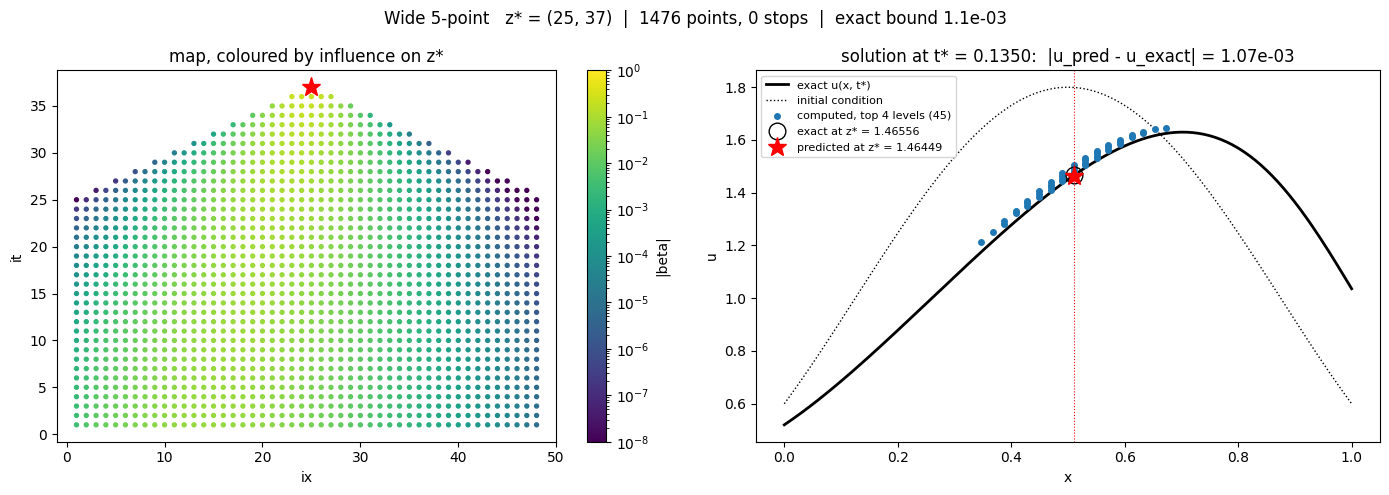

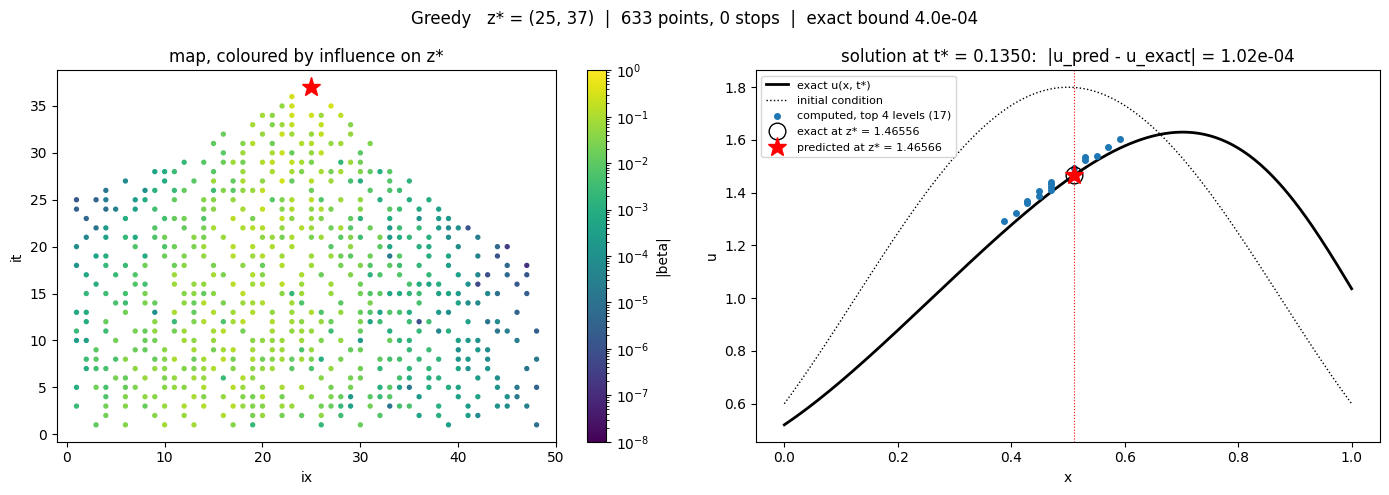

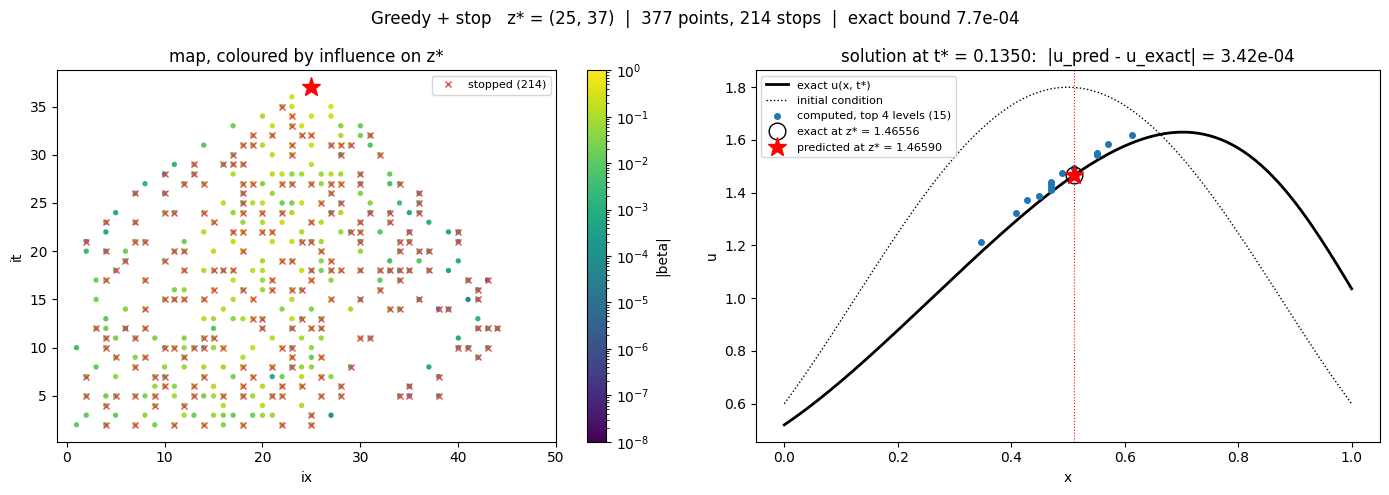

In [24]:
# ── One figure for any finished map (baselines, snapshots, training video) ──
#   left : the map, coloured by influence |beta| on z*; stopped points marked
#   right: the solution at t*: exact u(x, t*), the computed points of the top levels, and the value at z* (u_true ONLY here)
from matplotlib.colors import LogNorm

def plot_map(m, title="", path=None, top=4):
    z, rep = m["z_star"], report(m)
    u_hat = evaluate(m)
    P = np.array(list(m["stencil"]))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))

    sc = a1.scatter(P[:, 0], P[:, 1], c=[abs(m["beta"][tuple(p)]) for p in P], s=8, cmap="viridis", norm=LogNorm(1e-8, 1))
    if m["stopped"]:
        S = np.array(list(m["stopped"]))
        a1.plot(S[:, 0], S[:, 1], "x", color="#e34948", ms=4, label=f"stopped ({len(S)})")
        a1.legend(fontsize=8)
    a1.plot(*z, "r*", ms=14)
    fig.colorbar(sc, ax=a1, label="|beta|")
    a1.set_xlim(-1, nx); a1.set_xlabel("ix"); a1.set_ylabel("it"); a1.set_title("map, coloured by influence on z*")

    xf = np.linspace(0, 1, 201)
    a2.plot(xf, u_true(xf, z[1] * dt), "k-", lw=2, label="exact u(x, t*)")
    a2.plot(xf, u0(xf), "k:", lw=1, label="initial condition")
    near = [p for p in u_hat if p[1] >= z[1] - top]
    a2.plot([p[0] * dx for p in near], [u_hat[p] for p in near], "o", color="C0", ms=4, label=f"computed, top {top} levels ({len(near)})")
    a2.plot(z[0] * dx, Ug(z), "ko", ms=12, mfc="none", label=f"exact at z* = {Ug(z):.5f}")
    a2.plot(z[0] * dx, u_hat[z], "r*", ms=14, label=f"predicted at z* = {u_hat[z]:.5f}")
    a2.axvline(z[0] * dx, color="r", ls=":", lw=0.8)
    a2.set_xlabel("x"); a2.set_ylabel("u"); a2.legend(fontsize=8)
    a2.set_title(f"solution at t* = {z[1] * dt:.4f}:  |u_pred - u_exact| = {rep['error']:.2e}")

    fig.suptitle(f"{title}   z* = {z}  |  {rep['points']} points, {len(m['stopped'])} stops  |  exact bound {rep['bound']:.1e}")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=100, bbox_inches="tight"); plt.close(fig)
    else:
        plt.show()

z = (25, 37)
for name, rule in [("Wide 5-point", wide), ("Greedy", greedy_rule(1.0)), ("Greedy + stop", greedy_stop_rule(1.0))]:
    plot_map(build_map(z, rule), name)

### Training helpers
- `make_env`: one training environment (action mask + episode monitor); the switches (`stops`, `shaping`, `points_cost`) are passed through.
- `run_policy`: one episode with the policy's most likely picks, **without shaping** (the real return), same switches otherwise.
- `MapLogCallback`: points, accuracy term, stops, mean depth and finish rate of the training episodes (mean of the last 100) → TensorBoard.
- `SnapshotCallback`: every `every` steps, the policy at the training query and at one unseen query (watching only): numbers, map figure, checkpoint. The checkpoint with the best **training-query return** is kept as `best` (no exact solution in the selection); the last model is always reported too.

Check: a tiny run (2 environments, 512 steps, one snapshot).

In [29]:
# ── Training helpers ──
import json

def make_env(queries, seed, **env_kw):
    """One training environment (with the action mask and the episode monitor). env_kw: stops, shaping, points_cost, lam_range."""
    def _init():
        env = Monitor(ActionMasker(MapEnv(queries=queries, **env_kw), lambda e: e.action_masks()))
        env.reset(seed=seed)
        return env
    return _init

def run_policy(model, z, **env_kw):
    """One episode on z* with the policy's most likely picks, WITHOUT shaping (the real return). Returns the finished env."""
    env = MapEnv(queries=[z], **{**env_kw, "shaping": None})
    obs, _ = env.reset(seed=0)
    done, ret = False, 0.0
    while not done:
        act, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
        obs, r, done, _, info = env.step(act)
        ret += r
    env.ret, env.info = ret, info
    return env

# ── Callback 1: numbers of every finished training episode, mean of the last 100, to TensorBoard ──
class MapLogCallback(BaseCallback):
    KEYS = ("points_ratio", "score_ratio", "stops", "depth", "finished")
    def __init__(self):
        super().__init__()
        self.hist = {k: [] for k in self.KEYS}
    def _on_step(self):
        for info, done in zip(self.locals["infos"], self.locals["dones"]):
            if done and "points_ratio" in info:
                for k in self.KEYS:
                    self.hist[k].append(float(info[k]))
                    self.logger.record(f"map/{k}", np.mean(self.hist[k][-100:]))
        return True

# ── Callback 2: every `every` steps, the deterministic policy on the training query and one unseen query ──
#   saves the map figures and a checkpoint; keeps the checkpoint with the best TRAINING-query return as "best"
#   (selection uses estimates only; the unseen query and the true error are for watching, never for selection)
class SnapshotCallback(BaseCallback):
    def __init__(self, every, z_train, z_watch, folder, env_kw):
        super().__init__()
        self.every, self.z_train, self.z_watch, self.folder, self.env_kw = every, z_train, z_watch, folder, env_kw
        self.next, self.best, self.rows = every, -np.inf, []
        os.makedirs(folder, exist_ok=True)
    def _on_step(self):
        if self.num_timesteps < self.next:
            return True
        self.next += self.every
        steps = self.num_timesteps
        self.model.save(os.path.join(self.folder, f"ckpt_{steps}"))
        for z in (self.z_train, self.z_watch):
            env = run_policy(self.model, z, **self.env_kw)
            rep = report(env.m)
            row = {"steps": steps, "z": list(z), "return": env.ret, "points": rep["points"], "stops": env.info["stops"],
                   "depth": env.info["depth"], "error": rep["error"], "bound": rep["bound"]}
            self.rows.append(row)
            tag = "train" if z == self.z_train else "watch"
            for k in ("return", "points", "stops", "depth", "error", "bound"):
                self.logger.record(f"snap_{tag}/{k}", row[k])
            plot_map(env.m, f"{steps:,} steps ({tag})", path=os.path.join(self.folder, f"snap_{tag}_{steps:09d}.png"))
            print(f"{steps:>10,} | {tag} z* = {z}: return {env.ret:7.3f}, {rep['points']} points, {env.info['stops']} stops, "
                  f"depth {env.info['depth']:.2f}, error {rep['error']:.2e}, bound {rep['bound']:.2e}")
            if z == self.z_train and env.ret > self.best:
                self.best = env.ret
                self.model.save(os.path.join(self.folder, "best"))
        with open(os.path.join(self.folder, "snapshots.json"), "w") as f:
            json.dump(self.rows, f)
        return True

# ── Check: a tiny run (2 environments, 512 steps, one snapshot) to see that everything connects ──
_kw = dict(stops=True, shaping="height", points_cost="step")
_vec = SubprocVecEnv([make_env([(25, 37)], seed=s, **_kw) for s in range(2)])
_model = MaskablePPO("MlpPolicy", _vec, n_steps=256, batch_size=256, gamma=1.0, gae_lambda=0.97, verbose=0)
_snap = SnapshotCallback(512, (25, 37), (25, 75), os.path.join("runs_test", "nb14_check"), _kw)
_model.learn(512, callback=[MapLogCallback(), _snap])
_vec.close()
print("tiny run done:", len(_snap.rows), "snapshot rows")

       512 | train z* = (25, 37): return  -5.570, 1394 points, 1 stops, depth 1.91, error 6.17e-04, bound 3.80e-03
       512 | watch z* = (25, 75): return  -8.694, 3196 points, 3 stops, depth 1.98, error 1.58e-03, bound 6.72e-03
tiny run done: 2 snapshot rows


In [ ]:
# ── Training: the menu agent on the PASS-1 guess (only change from 14.1), seeds 1, 3, 5, 10M steps each ──
#   each run is skipped if its final.zip exists and resumes from its newest checkpoint after a crash
RUN_ROOT = f"runs{date.today():%m-%d}"
Z_TRAIN, Z_WATCH = (25, 37), (25, 75)
SEEDS, STEPS, EVERY, N_ENVS = (1, 3, 5), 10_000_000, 100_000, 8
PPO_KW = dict(n_steps=1024, batch_size=1024, gamma=1.0, gae_lambda=1.0, learning_rate=3e-4, ent_coef=0.0)
KW = dict(stops=False, shaping=None, points_cost="step", menu=MENU)
seed_dir = lambda name, z, seed: os.path.join(RUN_ROOT, f"nb15_{name}_z{z[0]}-{z[1]}_eps{EPS:.0e}_seed{seed}_2dt_pass1")

def train(name, queries, z_select, kw, seed, steps):
    """One training run on `queries`; snapshots (and best.zip) on z_select and Z_WATCH."""
    folder = seed_dir(name, z_select, seed)
    if os.path.exists(os.path.join(folder, "final.zip")):
        print(f"{name} seed {seed}: already done, skipped", flush=True); return
    vec = SubprocVecEnv([make_env(queries, seed=seed * 100 + i, **kw) for i in range(N_ENVS)])
    snap = SnapshotCallback(EVERY, z_select, Z_WATCH, folder, kw)
    ckpts = [f for f in os.listdir(folder) if f.startswith("ckpt_")] if os.path.isdir(folder) else []
    if ckpts:                                                          # resume after a crash
        model = MaskablePPO.load(os.path.join(folder, max(ckpts, key=lambda f: int(f[5:-4]))), env=vec, tensorboard_log=RUN_ROOT)
        snap.rows = json.load(open(os.path.join(folder, "snapshots.json")))
        snap.best = max(r["return"] for r in snap.rows if tuple(r["z"]) == z_select)
        snap.next = model.num_timesteps + EVERY
    else:
        model = MaskablePPO("MlpPolicy", vec, seed=seed, verbose=0, tensorboard_log=RUN_ROOT, **PPO_KW)
    t0 = time.time()
    print(f"=== {name} seed {seed}: {model.num_timesteps:,} -> {steps:,} steps -> {folder}", flush=True)
    model.learn(steps - model.num_timesteps, callback=[MapLogCallback(), snap], tb_log_name=os.path.basename(folder),
                reset_num_timesteps=not ckpts)
    model.save(os.path.join(folder, "final")); vec.close()
    print(f"=== {name} seed {seed}: done in {(time.time() - t0) / 60:.0f} min", flush=True)

print(f"menu: {len(MENU)} shapes (should be 521: greedy's shapes on the pass-1 guess)")
for seed in SEEDS:
    try:
        train("menu", [Z_TRAIN], Z_TRAIN, KW, seed, STEPS)
    except Exception as e:                                             # one failing seed must not stop the night
        print(f"=== menu seed {seed}: FAILED: {e!r}", flush=True)

menu: 521 shapes (should be 521: greedy's shapes on the pass-1 guess)
=== menu seed 1: 0 -> 10,000,000 steps -> runs11-12\nb15_menu_z25-37_eps1e-03_seed1_2dt_pass1
   100,000 | train z* = (25, 37): return  -2.175, 1329 points, 0 stops, depth 1.73, error 1.55e-04, bound 1.14e-03
   100,000 | watch z* = (25, 75): return  -3.633, 3153 points, 0 stops, depth 1.76, error 1.10e-03, bound 2.17e-03
   200,000 | train z* = (25, 37): return  -2.115, 1369 points, 0 stops, depth 1.59, error 1.99e-04, bound 8.65e-04
   200,000 | watch z* = (25, 75): return  -2.798, 3193 points, 0 stops, depth 1.61, error 2.61e-04, bound 1.61e-03
   300,000 | train z* = (25, 37): return  -3.298, 1523 points, 0 stops, depth 1.31, error 1.37e-04, bound 1.98e-03
   300,000 | watch z* = (25, 75): return  -5.729, 3342 points, 0 stops, depth 1.30, error 2.51e-03, bound 3.89e-03
   400,000 | train z* = (25, 37): return  -1.574, 1346 points, 0 stops, depth 1.68, error 5.61e-04, bound 7.20e-04
   400,000 | watch z* = (25, 75